In [1]:
import pandas as pd
dataset = pd.read_csv("Preplacementdata.csv")
import warnings
warnings.filterwarnings("ignore")

In [2]:
dataset.isnull().sum()

sl_no             0
ssc_p             0
hsc_p             0
degree_p          0
etest_p           0
mba_p             0
salary            0
gender            0
ssc_b             0
hsc_b             0
hsc_s             0
degree_t          0
workex            0
specialisation    0
status            0
dtype: int64

In [3]:
dataset

,sl_no,ssc_p,hsc_p,degree_p,etest_p,mba_p,salary,gender,ssc_b,hsc_b,hsc_s,degree_t,workex,specialisation,status
0,1.0,67.00,91.00,58.00,55.0,58.80,270000.0,M,Others,Others,Commerce,Sci&Tech,No,Mkt&HR,Placed
1,2.0,79.33,78.33,77.48,86.5,66.28,200000.0,M,Central,Others,Science,Sci&Tech,Yes,Mkt&Fin,Placed
2,3.0,65.00,68.00,64.00,75.0,57.80,250000.0,M,Central,Central,Arts,Comm&Mgmt,No,Mkt&Fin,Placed
3,4.0,56.00,52.00,52.00,66.0,59.43,0.0,M,Central,Central,Science,Sci&Tech,No,Mkt&HR,Not Placed
4,5.0,85.80,73.60,73.30,96.8,55.50,425000.0,M,Central,Central,Commerce,Comm&Mgmt,No,Mkt&Fin,Placed
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
210,211.0,80.60,82.00,77.60,91.0,74.49,400000.0,M,Others,Others,Commerce,Comm&Mgmt,No,Mkt&Fin,Placed
211,212.0,58.00,60.00,72.00,74.0,53.62,275000.0,M,Others,Others,Science,Sci&Tech,No,Mkt&Fin,Placed
212,213.0,67.00,67.00,73.00,59.0,69.72,295000.0,M,Others,Others,Commerce,Comm&Mgmt,Yes,Mkt&Fin,Placed
213,214.0,74.00,66.00,58.00,70.0,60.23,204000.0,F,Others,Others,Commerce,Comm&Mgmt,No,Mkt&HR,Placed


In [4]:
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import norm

<Axes: xlabel='ssc_p', ylabel='Density'>

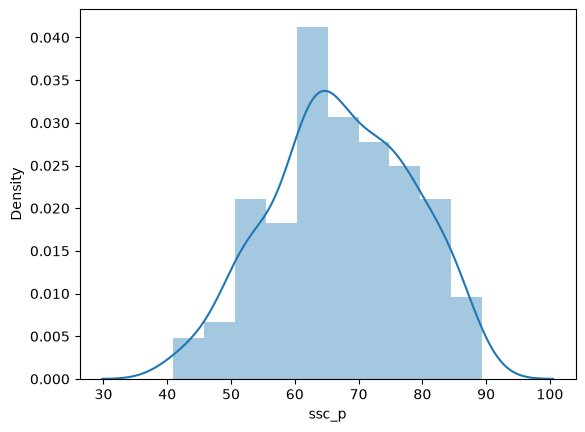

In [5]:
sns.distplot(dataset["ssc_p"])

In [6]:
def get_pdf_probability(dataset, startrange, endrange):

    sample = dataset.dropna()

    sample_mean = sample.mean()
    sample_std = sample.std()

    # Plot histogram
    fig, ax = plt.subplots()

    sns.histplot(sample, stat="density", color="green", ax=ax)
    sns.kdeplot(sample, color="blue", ax=ax)

    # Mark start and end ranges
    ax.axvline(startrange, color="red")
    ax.axvline(endrange, color="red")

    # Normal distribution
    dist = norm(loc=sample_mean, scale=sample_std)

    # Calculate probability between two values
    prob = dist.cdf(endrange) - dist.cdf(startrange)

    plt.show()

    return prob

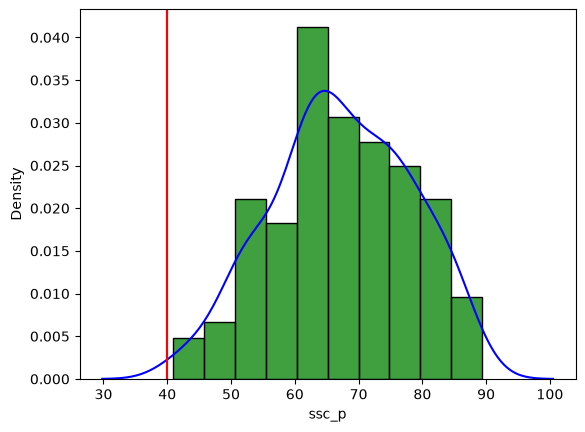

np.float64(0.0)

In [7]:
get_pdf_probability(dataset["ssc_p"],40,40)

In [8]:
from statsmodels.distributions.empirical_distribution import ECDF
ecdf = ECDF(dataset['ssc_p'])
ecdf(78)

np.float64(0.827906976744186)

In [19]:
def stdNBgraph(dataset):
    import seaborn as sns
    mean=dataset.mean()
    std=dataset.std()
    values = [i for i in dataset]
    z_score=[((j-mean)/std) for j in values]
    sns.distplot(z_score,kde=True)
    sum(z_score)/len(z_score)
    

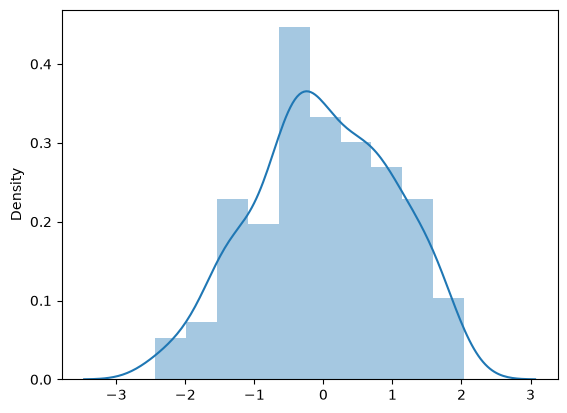

In [20]:
stdNBgraph(dataset['ssc_p'])